In [1]:
print("Hello, Teknik Fisika!")

Hello, Teknik Fisika!


In [2]:
mass = 2.5                 # float (setara double di C)
count = 5                  # int
sensor = "Sensor-A"        # string (char[] di C)
active = True              # bool (stdbool.h di C)

print(type(mass), type(count), type(sensor), type(active))
print(7 / 2, 7 // 2, 7 % 2, 2 ** 10)
print(0.1 + 0.2)

<class 'float'> <class 'int'> <class 'str'> <class 'bool'>
3.5 3 1 1024
0.30000000000000004


In [3]:
temperature = float(input("Temperatur (C): "))

if temperature < 20:
    status = "DINGIN"
elif temperature <= 30:
    status = "NORMAL"
else:
    status = "PANAS"

print(f"Temperatur: {temperature:.1f} C -> {status}")

Temperatur (C): 27.4
Temperatur: 27.4 C -> NORMAL


In [4]:
x0, v0, a = 2.0, 5.0, 3.0   # m, m/s, m/s^2

print("t(s)   x(m)")
for t in range(0, 6):
    x = x0 + v0 * t + 0.5 * a * t**2
    print(f"{t:4d}  {x:8.2f}")

# metode Babilonia dengan while
target = 2.0
x, tol = 1.0, 1e-12
iterations = 0

while True:
    x_new = 0.5 * (x + target / x)
    iterations += 1
    if abs(x_new - x) < tol or iterations >= 100:
        break
    x = x_new

print(f"\nsqrt(2) ~= {x_new:.15f} after {iterations} iterations")

t(s)   x(m)
   0      2.00
   1      8.50
   2     18.00
   3     30.50
   4     46.00
   5     64.50

sqrt(2) ~= 1.414213562373095 after 6 iterations


In [5]:
def kinetic_energy(mass, velocity):
    """Hitung energi kinetik dari massa (kg) dan kecepatan (m/s)."""
    return 0.5 * mass * velocity**2

def momentum(mass, velocity):
    return mass * velocity

print(f"Ek = {kinetic_energy(2.0, 3.0):.2f} J")
print(f"p  = {momentum(2.0, 3.0):.2f} kg.m/s")

Ek = 9.00 J
p  = 6.00 kg.m/s


In [6]:
voltage = [2.4, 3.1, 2.8, 3.5, 4.0]
voltage.append(3.7)

print("n   =", len(voltage))
print("min =", min(voltage), "max =", max(voltage))
print("mean=", f"{sum(voltage) / len(voltage):.3f}")
print("first:", voltage[0], "last:", voltage[-1])

for i, v in enumerate(voltage):
    print(f"V[{i}] = {v:.1f}")

n   = 6
min = 2.4 max = 4.0
mean= 3.250
first: 2.4 last: 3.7
V[0] = 2.4
V[1] = 3.1
V[2] = 2.8
V[3] = 3.5
V[4] = 4.0
V[5] = 3.7


In [7]:
time, voltage = [], []

with open("voltage.dat", "r", encoding="utf-8") as f:
    for line in f:
        if line.strip().startswith("#"):
            continue
        t_str, v_str = line.split()
        time.append(float(t_str))
        voltage.append(float(v_str))

print("samples:", len(time))
print(f"V[0] = {voltage[0]:.3f} V, V[end] = {voltage[-1]:.3f} V")
print(f"V_mean = {sum(voltage) / len(voltage):.3f} V")

samples: 11
V[0] = 1.984 V, V[end] = 2.483 V
V_mean = 2.463 V


In [8]:
import numpy as np

mass = np.array([1.0, 2.0, 3.0, 4.0])          # kg
velocity = np.array([2.0, 3.0, 1.5, 0.5])      # m/s

energy = 0.5 * mass * velocity**2
print("energy (J):", energy)
print("total     :", energy.sum(), "J")

# perbandingan jika hanya memakai list
energy_list = [0.5 * m * v**2 for m, v in zip([1.0, 2.0, 3.0, 4.0], [2.0, 3.0, 1.5, 0.5])]
print("list      :", energy_list)

energy (J): [2.    9.    3.375 0.5  ]
total     : 14.875 J
list      : [2.0, 9.0, 3.375, 0.5]


In [9]:
import numpy as np

t = np.linspace(0.0, 2.0, 21)          # 21 titik, langkah 0.1 s
y = 2.0 + 3.0 * t - 0.5 * 9.81 * t**2  # gerak vertikal (m)

print("number of points:", t.size)
print("t[:4] =", t[:4])
print("y[:4] =", np.round(y[:4], 3))
print(f"mean = {y.mean():.3f}, std = {y.std():.3f}, max = {y.max():.3f}")

number of points: 21
t[:4] = [0.  0.1 0.2 0.3]
y[:4] = [2.    2.251 2.404 2.459]
mean = -1.704, std = 4.424, max = 2.459


In [10]:
import numpy as np

T = np.array([28.4, 30.2, 29.8, 31.5, 30.9, 28.4, 33.0])

high = T > 30.0
print("mask      :", high)
print("above 30 C:", T[high])
print("percentage:", f"{np.count_nonzero(high) / T.size * 100:.1f} %")
print("mean(high):", f"{T[high].mean():.2f} C")

outside = (T < 29.0) | (T > 31.0)
print("outside 29-31 C:", T[outside])

mask      : [False  True False  True  True False  True]
above 30 C: [30.2 31.5 30.9 33. ]
percentage: 57.1 %
mean(high): 31.40 C
outside 29-31 C: [28.4 31.5 28.4 33. ]


In [11]:
import numpy as np

volt = np.loadtxt("voltage.dat")
print("voltage.dat shape:", volt.shape)

data = np.genfromtxt("motion.csv", delimiter=",", names=True)
print("columns:", data.dtype.names)
t = data["time_s"]
x = data["position_m"]
print("samples:", t.size)

voltage.dat shape: (11, 2)
columns: ('time_s', 'position_m')
samples: 11


In [12]:
import numpy as np

data = np.genfromtxt("motion.csv", delimiter=",", names=True)
t, x = data["time_s"], data["position_m"]

dt = np.diff(t)
if np.any(dt <= 0):
    raise ValueError("time must increase strictly")

v = np.diff(x) / dt
k = np.argmax(np.abs(v))
first = np.argmax(v > 2.0)

print("v =", np.round(v, 4))
print(f"max |v| = {np.abs(v[k]):.4f} m/s in [{t[k]:.2f}, {t[k+1]:.2f}]")
print(f"global average velocity = {(x[-1] - x[0]) / (t[-1] - t[0]):.4f} m/s")
print(f"arithmetic mean of v  = {v.mean():.4f} m/s")
print(f"|v| > 2 m/s first in [{t[first]:.2f}, {t[first+1]:.2f}]")

v = [1.375 1.725 2.075 2.425 2.775 3.125 3.475 3.825 4.175 4.525]
max |v| = 4.5250 m/s in [4.50, 5.00]
global average velocity = 2.9500 m/s
arithmetic mean of v  = 2.9500 m/s
|v| > 2 m/s first in [1.00, 1.50]


saved gerak-posisi.pdf


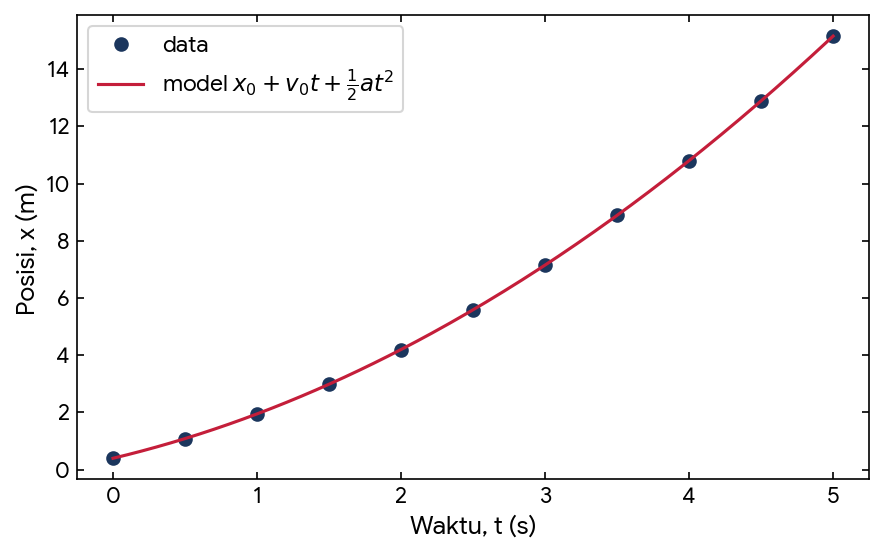

In [13]:
import numpy as np
import matplotlib.pyplot as plt

data = np.genfromtxt("motion.csv", delimiter=",", names=True)
t, x = data["time_s"], data["position_m"]

t_model = np.linspace(0.0, 5.0, 200)
x_model = 0.4 + 1.2 * t_model + 0.5 * 0.7 * t_model**2

fig, ax = plt.subplots(figsize=(6.0, 3.8))
ax.plot(t, x, "o", color="#1b365d", label="data")
ax.plot(t_model, x_model, "-", color="#c41e3a",
        label=r"model $x_0 + v_0 t + \frac{1}{2} a t^2$")
ax.set_xlabel("Waktu, t (s)", fontsize=12)
ax.set_ylabel("Posisi, x (m)", fontsize=12)
ax.tick_params(direction="in", top=True, right=True, labelsize=11)
ax.legend(fontsize=11)
fig.tight_layout()
fig.savefig("gerak-posisi.pdf")
print("saved gerak-posisi.pdf")

samples        : 16
initial / final: 86.00 C / 29.62 C
all rates < 0  : True
fastest cooling: -4.585 C/min in [0, 2] min
slowest cooling: -0.490 C/min in [28, 30] min


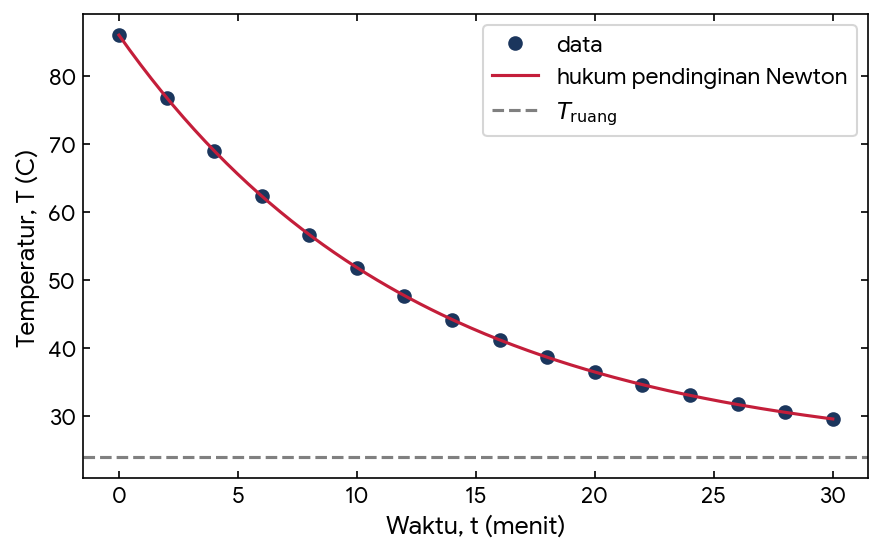

In [14]:
import numpy as np
import matplotlib.pyplot as plt

data = np.genfromtxt("cooling.csv", delimiter=",", names=True)
t, T = data["time_min"], data["temperature_C"]

rate = np.diff(T) / np.diff(t)
k = np.argmin(rate)
m = np.argmax(rate)

print("samples        :", t.size)
print(f"initial / final: {T[0]:.2f} C / {T[-1]:.2f} C")
print("all rates < 0  :", bool(np.all(rate < 0)))
print(f"fastest cooling: {rate[k]:.3f} C/min in [{t[k]:.0f}, {t[k+1]:.0f}] min")
print(f"slowest cooling: {rate[m]:.3f} C/min in [{t[m]:.0f}, {t[m+1]:.0f}] min")

t_model = np.linspace(0, 30, 200)
T_model = 24.0 + (86.0 - 24.0) * np.exp(-0.08 * t_model)

fig, ax = plt.subplots(figsize=(6.0, 3.8))
ax.plot(t, T, "o", color="#1b365d", label="data")
ax.plot(t_model, T_model, "-", color="#c41e3a", label="hukum pendinginan Newton")
ax.axhline(24.0, color="gray", linestyle="--", label=r"$T_{\mathrm{ruang}}$")
ax.set_xlabel("Waktu, t (menit)", fontsize=12)
ax.set_ylabel("Temperatur, T (C)", fontsize=12)
ax.tick_params(direction="in", top=True, right=True, labelsize=11)
ax.legend(fontsize=11)
fig.tight_layout()
fig.savefig("pendinginan.pdf")

samples = 201, duration = 2.00 s
amplitude = 0.09980 cm
RMS       = 0.07053 cm
A/sqrt(2) = 0.07057 cm
sign changes = 0


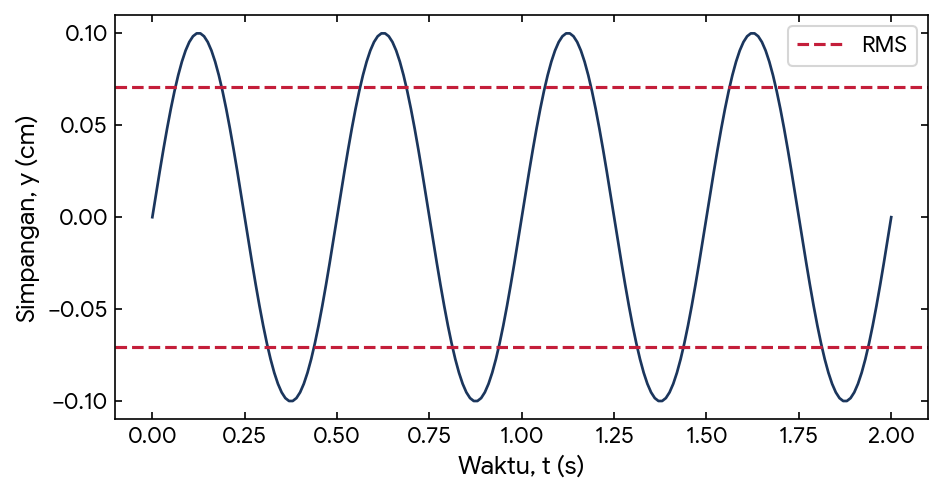

In [15]:
import numpy as np
import matplotlib.pyplot as plt

data = np.genfromtxt("oscillation.csv", delimiter=",", names=True)
t, y = data["time_s"], data["displacement_cm"]

amplitude = 0.5 * (y.max() - y.min())
rms = np.sqrt(np.mean(y**2))
A_over_sqrt2 = amplitude / np.sqrt(2.0)
signs = np.sign(y[:-1]) * np.sign(y[1:]) < 0

print(f"samples = {y.size}, duration = {t[-1] - t[0]:.2f} s")
print(f"amplitude = {amplitude:.5f} cm")
print(f"RMS       = {rms:.5f} cm")
print(f"A/sqrt(2) = {A_over_sqrt2:.5f} cm")
print("sign changes =", int(np.count_nonzero(signs)))

fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.plot(t, y, "-", color="#1b365d", linewidth=1.3)
ax.axhline(rms, color="#c41e3a", linestyle="--", label="RMS")
ax.axhline(-rms, color="#c41e3a", linestyle="--")
ax.set_xlabel("Waktu, t (s)", fontsize=12)
ax.set_ylabel("Simpangan, y (cm)", fontsize=12)
ax.tick_params(direction="in", top=True, right=True, labelsize=11)
ax.legend(fontsize=11, loc="upper right")
fig.tight_layout()
fig.savefig("gelombang.pdf")

a  = 0.7000 m/s^2
v0 = 1.2000 m/s


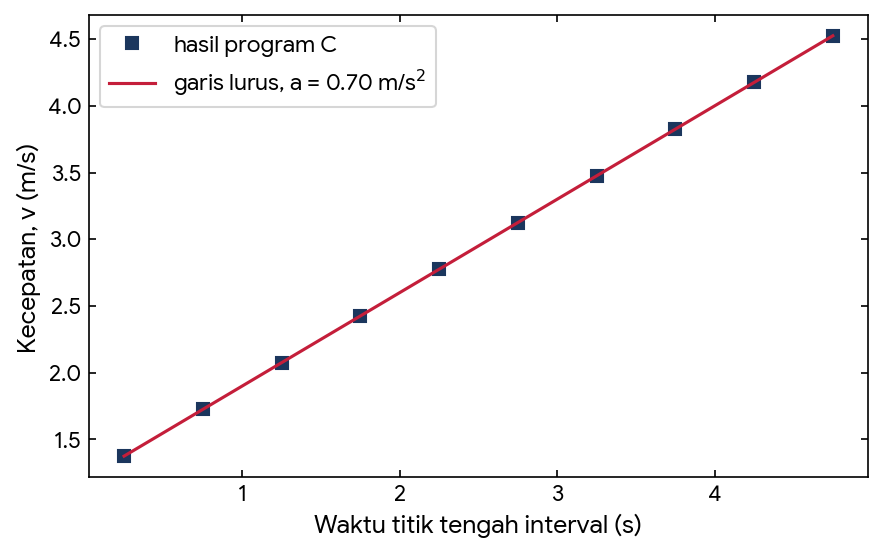

In [16]:
import numpy as np
import matplotlib.pyplot as plt

data = np.genfromtxt("velocity.csv", delimiter=",", names=True)
t_mid = 0.5 * (data["time_start_s"] + data["time_end_s"])
v = data["velocity_m_per_s"]

slope, intercept = np.polyfit(t_mid, v, 1)
print(f"a  = {slope:.4f} m/s^2")
print(f"v0 = {intercept:.4f} m/s")

fig, ax = plt.subplots(figsize=(6.0, 3.8))
ax.plot(t_mid, v, "s", color="#1b365d", label="hasil program C")
ax.plot(t_mid, slope * t_mid + intercept, "-", color="#c41e3a",
        label=f"garis lurus, a = {slope:.2f} m/s$^2$")
ax.set_xlabel("Waktu titik tengah interval (s)", fontsize=12)
ax.set_ylabel("Kecepatan, v (m/s)", fontsize=12)
ax.tick_params(direction="in", top=True, right=True, labelsize=11)
ax.legend(fontsize=11)
fig.tight_layout()
fig.savefig("kecepatan.pdf")